# Telco Customer Churn 

## Phase 0: Cadrage métier
- **Objectif** : Prédire quels clients vont partir pour agir en amont
- **Cible** : colonne `Churn` (Yes/No) → classification binaire
- **Vigilance data leakage** : `customerID` à drop, `TotalCharges` à surveiller


## Phase 1: Inspection du dataset

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


sns.set_theme(style='darkgrid')

In [16]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.head())
print(df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [20]:
print(df.describe())
print("_"*60)
print("_"*60)
print(df.info())

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000
____________________________________________________________
____________________________________________________________
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5 

In [ ]:
mask = df['TotalCharges'].str.strip() == ''
print(df[mask][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])
print(f"\nNombre de lignes concernées : {mask.sum()}")

      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No

Nombre de lignes concernées : 11


In [23]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isnull().sum())

float64
11


In [24]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
print(df['Churn'].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [27]:
print(df.duplicated().sum())
print(f"customerID uniques : {df['customerID'].nunique()} / {len(df)}")

0
customerID uniques : 7043 / 7043


## Phase 2: Train/Test stratifié

In [31]:
x = df.drop(columns=['Churn', 'customerID'])
y = df['Churn']

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"train:{x_train.shape[0]}")
print(f"test:{x_test.shape[0]}")

train:5634
test:1409


In [32]:
print(f"Taux churn train : {y_train.mean()*100:.1f}%")
print(f"Taux churn test  : {y_test.mean()*100:.1f}%")

Taux churn train : 26.5%
Taux churn test  : 26.5%


## Phase 3: Analyse univariée

In [33]:
df_train = x_train.copy()
df_train['Churn'] = y_train.values
print(df_train.shape)

(5634, 20)


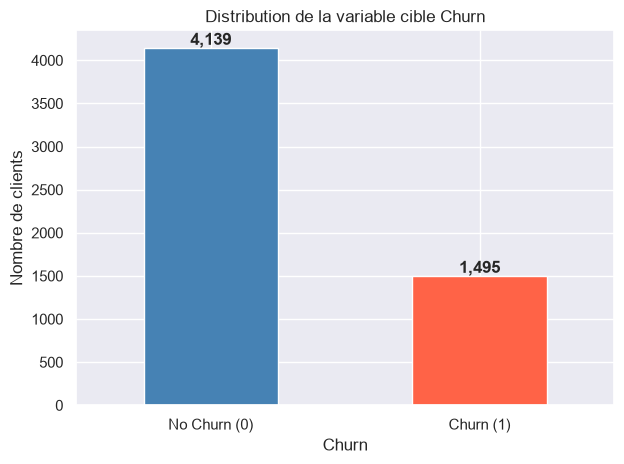

In [34]:
ax = df_train['Churn'].value_counts().plot(
    kind='bar',
    color=['steelblue', 'tomato'],
    edgecolor='white',
    width=0.5
)
ax.set_xticklabels(['No Churn (0)', 'Churn (1)'], rotation=0)
ax.set_title('Distribution de la variable cible Churn')
ax.set_ylabel('Nombre de clients')

for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', 
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

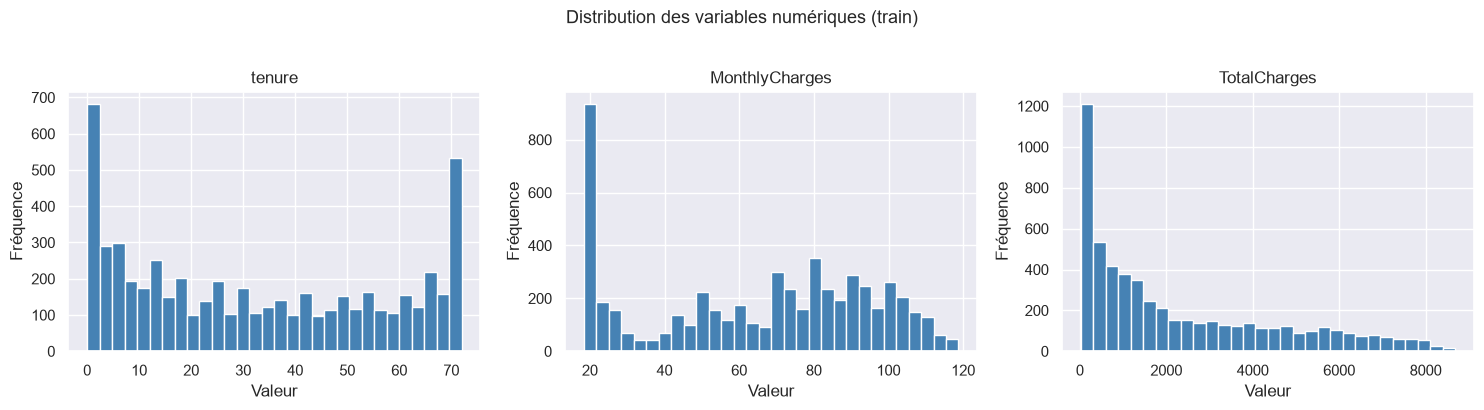

In [35]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    df_train[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('Valeur')
    ax.set_ylabel('Fréquence')

plt.suptitle('Distribution des variables numériques (train)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

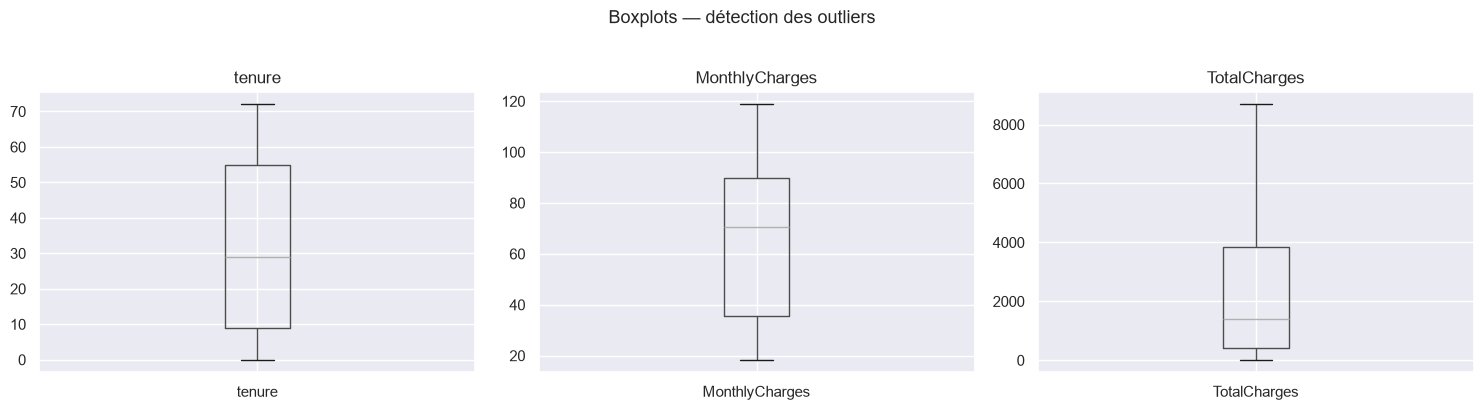

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    df_train.boxplot(column=col, ax=ax)
    ax.set_title(col)

plt.suptitle('Boxplots détection des outliers', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## Phase 4: Valeur manquante

In [37]:
nan_mask = df_train['TotalCharges'].isnull()
print(f"NaN dans TotalCharges: {nan_mask.sum()}")
print()
print(df_train[nan_mask][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

NaN dans TotalCharges: 8

      tenure  MonthlyCharges  TotalCharges  Churn
6670       0           73.35           NaN      0
4380       0           20.00           NaN      0
3826       0           25.35           NaN      0
488        0           52.55           NaN      0
1082       0           25.75           NaN      0
1340       0           56.05           NaN      0
6754       0           61.90           NaN      0
3331       0           19.85           NaN      0


In [38]:
df_train['TotalCharges'] = df_train['TotalCharges'].fillna(0)

print(f"NaN restants : {df_train['TotalCharges'].isnull().sum()}")

NaN restants : 0


## Phase 5: Analyse bivariée

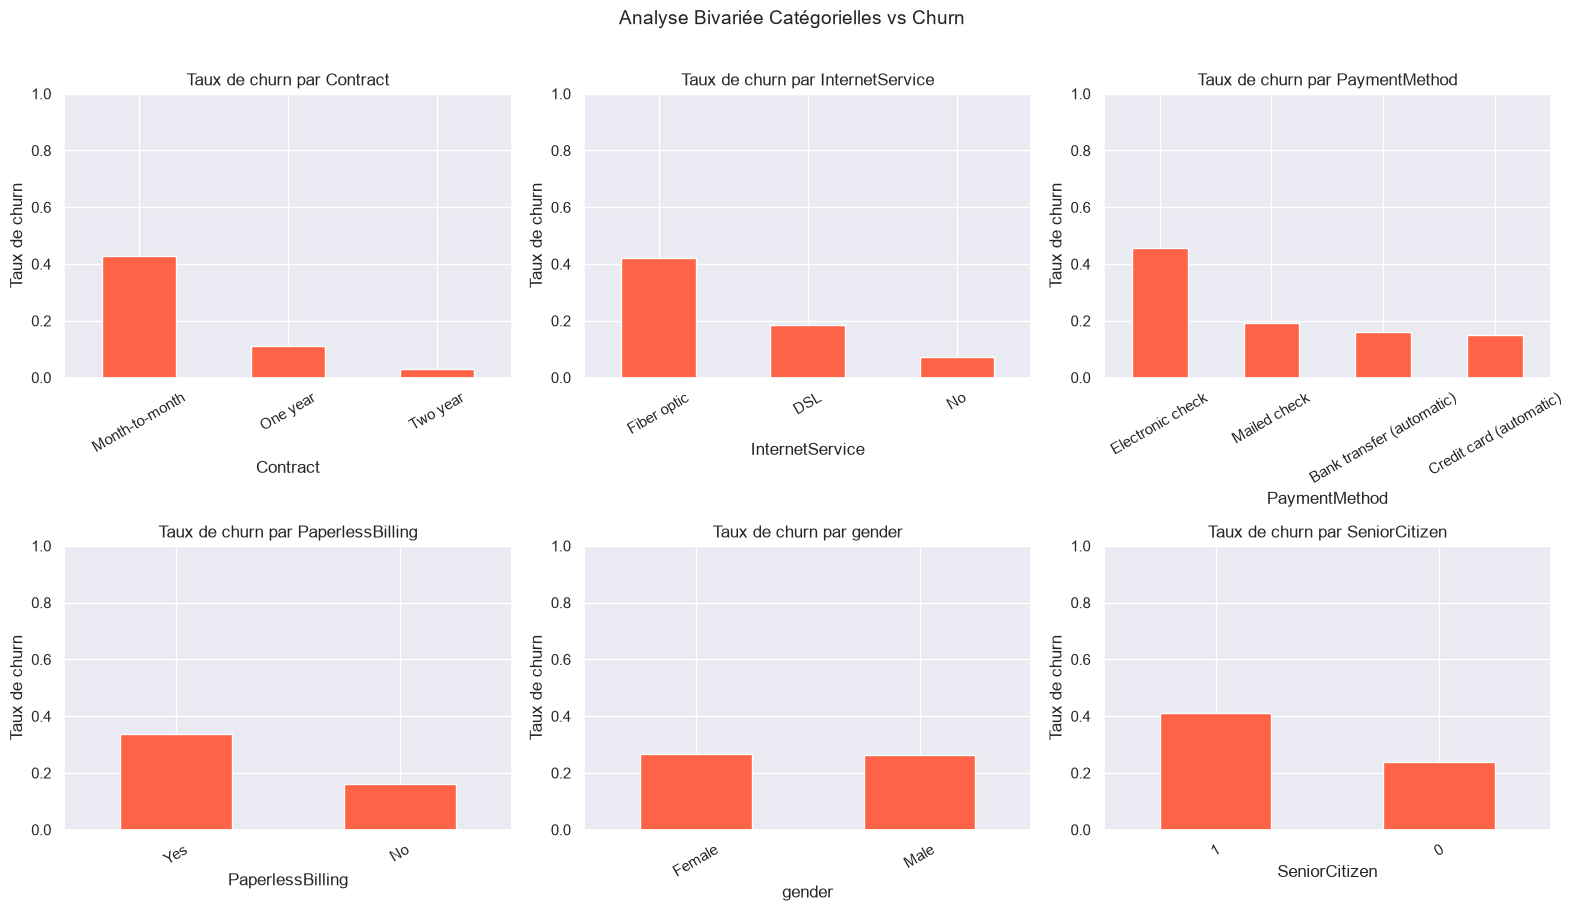

In [39]:
cat_cols = ['Contract', 'InternetService', 'PaymentMethod', 
            'PaperlessBilling', 'gender', 'SeniorCitizen']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    churn_rate = df_train.groupby(col)['Churn'].mean().sort_values(ascending=False)
    churn_rate.plot(kind='bar', ax=ax, color='tomato', edgecolor='white')
    ax.set_title(f'Taux de churn par {col}')
    ax.set_ylabel('Taux de churn')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Analyse Bivariée Catégorielles vs Churn', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

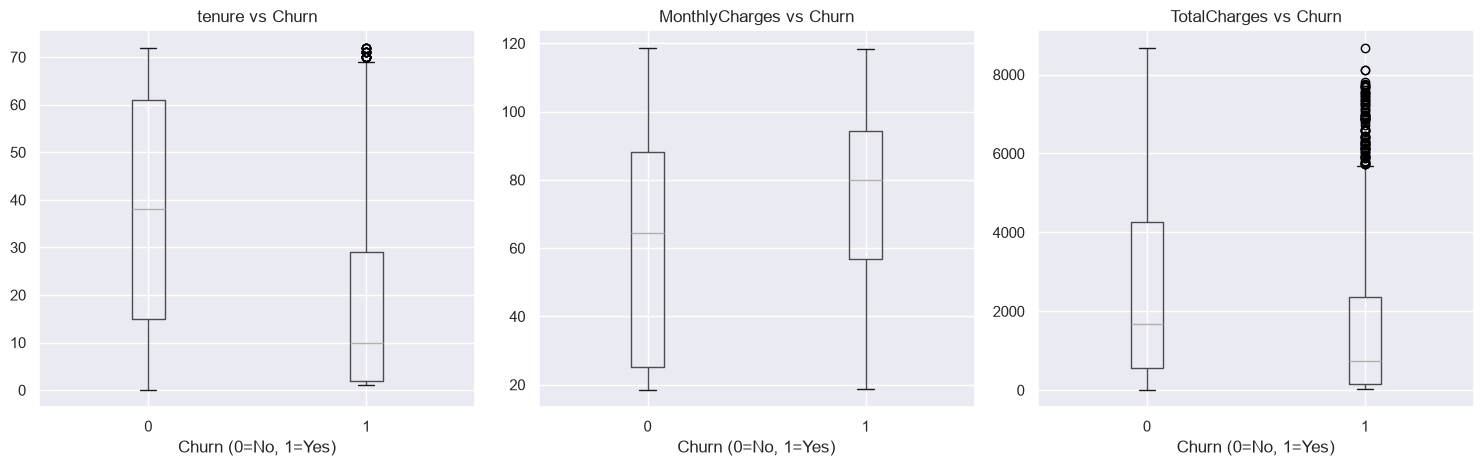

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, num_cols):
    df_train.boxplot(column=col, by='Churn', ax=ax)
    ax.set_title(f'{col} vs Churn')
    ax.set_xlabel('Churn (0=No, 1=Yes)')

plt.suptitle('')
plt.tight_layout()
plt.show()

## Phase 6: Analyse Multivariée

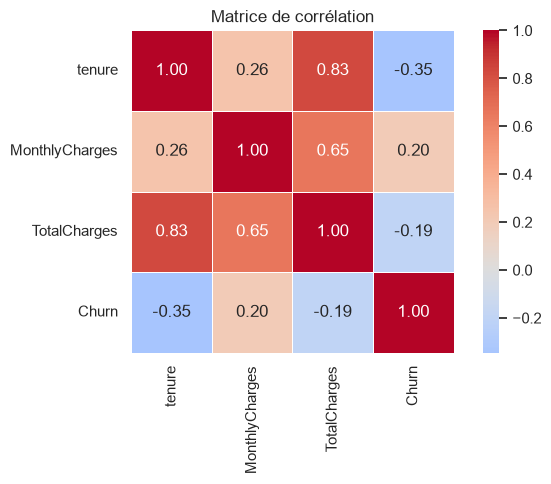

In [41]:
num_cols_with_target = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']

corr_matrix = df_train[num_cols_with_target].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', 
            cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

In [44]:
print("""
╔══════════════════════════════════════════════════════╗
║           SYNTHÈSE EDA DÉCISIONS FINALES             ║
╠══════════════════════════════════════════════════════╣
║  CIBLE : Churn binaire déséquilibre 73.5/26.5%       ║
║  → Métrique : F1-score, AUC-ROC                      ║
╠══════════════════════════════════════════════════════╣
║  VARIABLES FORTES :                                  ║
║    Contract, tenure, InternetService                 ║
║    PaymentMethod, MonthlyCharges                     ║
╠══════════════════════════════════════════════════════╣
║  VARIABLES FAIBLES  :                                ║
║    gender → peu discriminant                         ║
╠══════════════════════════════════════════════════════╣
║  PREPROCESSING À PRÉVOIR :                           ║
║    - Drop customerID                                 ║
║    - TotalCharges : colinéaire → à évaluer           ║
║    - Encoder catégorielles (OHE ou Label)            ║
║    - Scaler numériques (StandardScaler)              ║
║    - Gérer déséquilibre (class_weight ou SMOTE)      ║
╚══════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════╗
║           SYNTHÈSE EDA DÉCISIONS FINALES             ║
╠══════════════════════════════════════════════════════╣
║  CIBLE : Churn binaire déséquilibre 73.5/26.5%       ║
║  → Métrique : F1-score, AUC-ROC                      ║
╠══════════════════════════════════════════════════════╣
║  VARIABLES FORTES :                                  ║
║    Contract, tenure, InternetService                 ║
║    PaymentMethod, MonthlyCharges                     ║
╠══════════════════════════════════════════════════════╣
║  VARIABLES FAIBLES  :                                ║
║    gender → peu discriminant                         ║
╠══════════════════════════════════════════════════════╣
║  PREPROCESSING À PRÉVOIR :                           ║
║    - Drop customerID                                 ║
║    - TotalCharges : colinéaire → à évaluer           ║
║    - Encoder catégorielles (OHE ou Label)            ║
║    - Scaler numériques (Stan

## Preprocessing

In [45]:
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in x_train.columns if col not in num_features]

print("Numériques :", num_features)
print("Catégorielles :", cat_features)

Numériques : ['tenure', 'MonthlyCharges', 'TotalCharges']
Catégorielles : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
x_train_enc = pd.get_dummies(x_train, columns=cat_features, drop_first=True)
x_test_enc = pd.get_dummies(x_test, columns=cat_features, drop_first=True)

x_test_enc = x_test_enc.reindex(columns=x_train_enc.columns, fill_value=0)
print(f"Shape avant encoding : {x_train.shape}")
print(f"Shape après encoding : {x_train_enc.shape}")



Shape avant encoding : (5634, 19)
Shape après encoding : (5634, 30)


In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_enc[num_features] = scaler.fit_transform(x_train_enc[num_features])
x_test_enc[num_features] = scaler.transform(x_test_enc[num_features]) 

print("Scaling OK")
print(x_train_enc[num_features].describe().round(2))

Scaling OK
        tenure  MonthlyCharges  TotalCharges
count  5634.00         5634.00       5626.00
mean     -0.00           -0.00          0.00
std       1.00            1.00          1.00
min      -1.32           -1.54         -1.00
25%      -0.96           -0.97         -0.83
50%      -0.14            0.18         -0.40
75%       0.92            0.83          0.67
max       1.61            1.79          2.80


In [49]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np 

classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight='balanced',
                classes=classes,
                y=y_train
)

class_weight_dict = {0: weights[0], 1: weights[1]}
print(f"Poids classe 0 (No churn) : {weights[0]:.2f}")
print(f"Poids classe 1 (Churn)    : {weights[1]:.2f}")



Poids classe 0 (No churn) : 0.68
Poids classe 1 (Churn)    : 1.88


Nombre de variables en entrée (input_dim) : 30
NaN dans train : 8 | NaN dans test : 3


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.layers import Input


model = Sequential([
    Input(shape=(input_dim,)),       
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')  
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)